In [1]:
%load_ext autoreload
%autoreload 2

import sys
from pathlib import Path

# Add project root to path
project_root = Path.cwd().parent
if str(project_root) not in sys.path:
    sys.path.append(str(project_root))

from src.audio_classification.data import load_fma_metadata

# Load official metadata DataFrame
metadata_path = project_root / "data" / "raw" / "fma_metadata"
df = load_fma_metadata(str(metadata_path))

print("Metadata Shape:", df.shape)
print("\nGenre Breakdown:\n", df['genre'].value_counts())
print("\nOfficial Split Breakdown:\n", df['split'].value_counts())

Metadata Shape: (8000, 4)

Genre Breakdown:
 genre
Hip-Hop          1000
Pop              1000
Folk             1000
Experimental     1000
Rock             1000
International    1000
Electronic       1000
Instrumental     1000
Name: count, dtype: int64

Official Split Breakdown:
 split
training      6400
validation     800
test           800
Name: count, dtype: int64


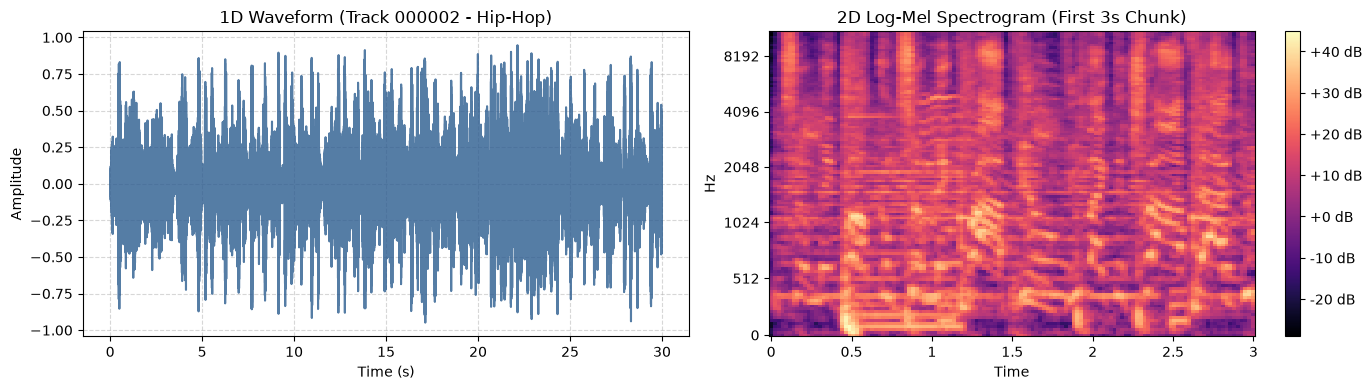

In [2]:
import librosa
import librosa.display
import matplotlib.pyplot as plt
import numpy as np
import torch
from pathlib import Path

from src.audio_classification.data import load_fma_metadata, get_audio_path
from src.audio_classification.features import MelSpectrogramExtractor

# Load sample track metadata
project_root = Path.cwd().parent
metadata_path = project_root / "data" / "raw" / "fma_metadata"
audio_dir = project_root / "data" / "raw" / "fma_small"

df_meta = load_fma_metadata(str(metadata_path))
sample_row = df_meta.iloc[0]
sample_audio_path = get_audio_path(str(audio_dir), sample_row["track_id"])

# 1. Load raw audio waveform (22.05 kHz)
y, sr = librosa.load(sample_audio_path, sr=22050, mono=True)

# 2. Compute Log-Mel Spectrogram
extractor = MelSpectrogramExtractor(sample_rate=22050)
spec_tensor = extractor.process_file(sample_audio_path) # Shape: [10, 1, 128, 130]
sample_spec = spec_tensor[0].squeeze().numpy() # First 3s chunk: [128, 130]

# Plot Waveform vs Spectrogram side-by-side
fig, axes = plt.subplots(1, 2, figsize=(14, 4))

# Subplot 1: Waveform
times = np.linspace(0, len(y) / sr, num=len(y))
axes[0].plot(times, y, color="#2b5c8f", alpha=0.8)
axes[0].set_title(f"1D Waveform (Track {sample_row['track_id']:06d} - {sample_row['genre']})")
axes[0].set_xlabel("Time (s)")
axes[0].set_ylabel("Amplitude")
axes[0].grid(True, linestyle="--", alpha=0.5)

# Subplot 2: Log-Mel Spectrogram
img = librosa.display.specshow(
    sample_spec,
    sr=sr,
    hop_length=512,
    x_axis="time",
    y_axis="mel",
    ax=axes[1],
    cmap="magma",
)
fig.colorbar(img, ax=axes[1], format="%+2.0f dB")
axes[1].set_title("2D Log-Mel Spectrogram (First 3s Chunk)")

plt.tight_layout()
plt.show()

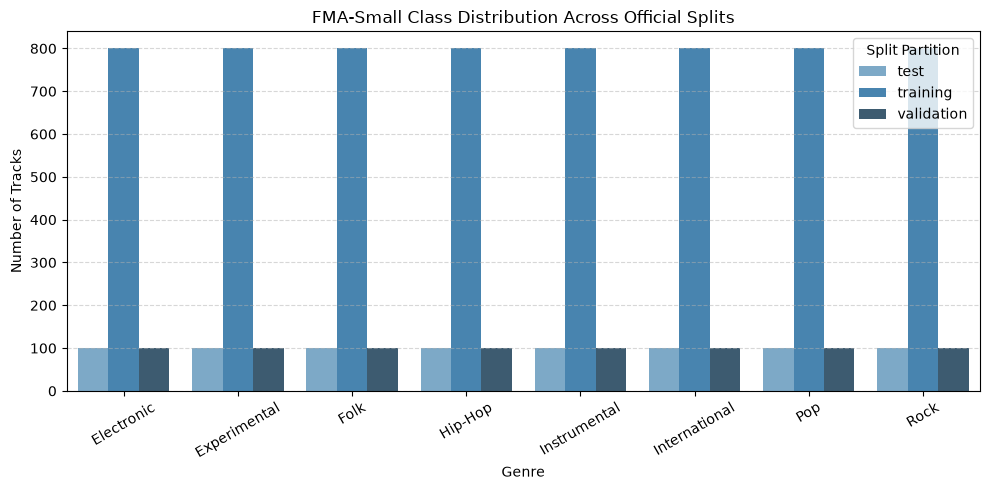

In [3]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

# Group track counts by genre and split
split_genre_counts = (
    df_meta.groupby(["genre", "split"])
    .size()
    .reset_index(name="count")
)

plt.figure(figsize=(10, 5))
sns.barplot(
    data=split_genre_counts,
    x="genre",
    y="count",
    hue="split",
    palette="Blues_d",
)
plt.title("FMA-Small Class Distribution Across Official Splits")
plt.xlabel("Genre")
plt.ylabel("Number of Tracks")
plt.xticks(rotation=30)
plt.legend(title="Split Partition")
plt.grid(axis="y", linestyle="--", alpha=0.5)
plt.tight_layout()
plt.show()